In [1]:
# conda env 'misr'

import MisrToolkit as mtk
import numpy as np
import matplotlib.pyplot as plt

# # These are some parameters to make figures nice (and big)
# params = {'legend.fontsize': 'x-large',
#          'axes.labelsize': 'x-large',
#          'axes.titlesize': 'x-large',
#          'xtick.labelsize': 'x-large',
#          'ytick.labelsize': 'x-large'}

# plt.rcParams.update(params)

In [2]:
def nearest_sample(lat, lon, path, resolution):
    region = mtk.MtkRegion(lat,lon, 1, 1, "km")
    lats, lons = region.snap_to_grid(path, resolution).create_latlon()
    lats = lats.ravel()
    lons = lons.ravel()
    lat_diff = lats - lat
    lon_diff = lons - lon
    D = (lat_diff**2 + lon_diff**2)**0.5
    return lats[np.argmin(D)], lons[np.argmin(D)]

In [3]:
database = '../../data/MISR'
tc_cloud_general = '{}/MISR_AM1_TC_CLOUD_P{:d}_O{:d}_F01_0001.hdf'
path = 117
orbit = 105254
close_lat = 19.845
close_lon = 120.4505
lat, lon = nearest_sample(close_lat, close_lon, path, 17600)
n = 17
region = mtk.MtkRegion(lat, lon, 8.8*n, 8.8*n, "km")
lat17600, lon17600 = region.snap_to_grid(path, 17600).create_latlon()
assert lat17600.shape[0] % 2 == 1
assert lon17600.shape[0] % 2 == 1
i_center_lat = int((lat17600.shape[0] - 1) / 2)
j_center_lon = int((lon17600.shape[1] - 1) / 2)

In [4]:
grp_general = '{}/MISR_AM1_GRP_ELLIPSOID_GM_P{:d}_O{:d}_{}_F03_0024.hdf'
nadir_file = grp_general.format(database, path, orbit, 'AN')
lat275, lon275 = region.snap_to_grid(path, 275).create_latlon()
brf = mtk.MtkFile(nadir_file).grid('RedBand').field('Red Brf').read(region).data()

In [5]:
tc_cloud_file = tc_cloud_general.format(database, path, orbit)
cmv_grid = mtk.MtkFile(tc_cloud_file).grid('Motion_17.6_km')
CTH = cmv_grid.field('CloudTopHeightOfMotion').read(region).data()
CTH[CTH == -9999] = 0
CMV_N = cmv_grid.field('CloudMotionNorthward').read(region).data()
CMV_N[CMV_N == -9999] = 0
CMV_E = cmv_grid.field('CloudMotionEastward').read(region).data()
CMV_E[CMV_E == -9999] = 0
CMV_Speed = (CMV_N**2 + CMV_E**2)**0.5

In [6]:
CTH

array([[557.01715, 497.6972 , 504.53735, 364.22372, 400.64774, 310.62524,
        381.6414 , 671.264  , 594.1347 ],
       [519.6308 , 450.19818, 350.63977, 537.8562 , 387.99487, 373.38422,
        510.5431 , 566.63586, 481.87268],
       [516.32245, 371.38528, 544.1461 , 573.1288 , 482.75076, 488.16776,
        494.11798, 468.82748, 478.27612],
       [326.9799 , 496.8845 , 539.2023 , 332.7049 , 432.02454, 494.69522,
        433.0131 , 466.54337, 400.39124],
       [302.48288, 335.50916, 459.17804, 447.4669 , 577.07983, 522.8805 ,
        533.456  , 566.018  , 418.51685],
       [309.6839 , 331.19028, 461.9431 , 411.22952, 426.0832 , 545.82404,
        444.92902, 374.54437,   0.     ],
       [399.2456 , 440.19797, 522.6183 , 474.7648 , 563.83606, 502.1429 ,
        520.70874, 351.03632,   0.     ],
       [531.3011 , 482.59674, 511.61108, 540.73627, 451.65698, 664.9719 ,
        699.93964,   0.     ,   0.     ],
       [541.42645, 687.83636, 647.5197 , 552.8866 , 367.84796, 415.8562 

Text(0, 0.5, 'Latitude (deg)')

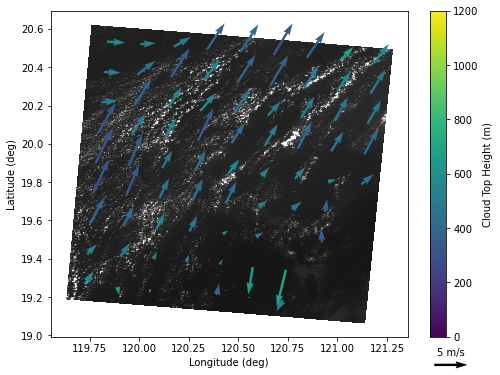

In [7]:
f, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(lon275, lat275, c=brf, marker='s', s=1, cmap='gray', vmin=0, vmax=0.3)
q = ax.quiver(lon17600, lat17600, CMV_E, CMV_N, CTH, units='xy', clim=(0, 1200))
ax.quiverkey(q, 0.82, 0.06, 5, '5 m/s', labelpos='N', coordinates='figure')
plt.colorbar(q, label='Cloud Top Height (m)')
ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')

Text(0, 0.5, 'Latitude (deg)')

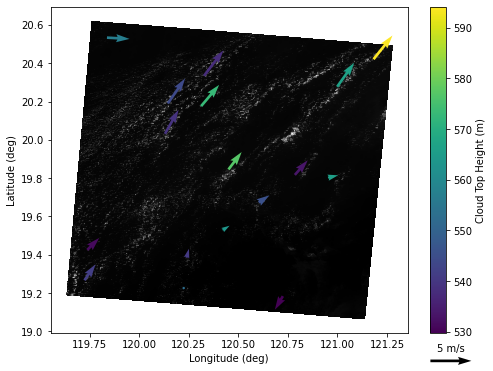

In [12]:
center_CTH = CTH[i_center_lat, j_center_lon]
half_bin = 50 # m
cond = (CTH > (center_CTH - half_bin)) & (CTH < (center_CTH + half_bin))
f, ax = plt.subplots(1, 1, figsize=(8, 6))
ax.scatter(lon275, lat275, c=brf, marker='s', s=1, cmap='gray')
q = ax.quiver(lon17600[cond], lat17600[cond], CMV_E[cond], CMV_N[cond], CTH[cond], units='xy')
ax.quiverkey(q, 0.82, 0.06, 5, '5 m/s', labelpos='N', coordinates='figure')
plt.colorbar(q, label='Cloud Top Height (m)')
ax.set_xlabel('Longitude (deg)')
ax.set_ylabel('Latitude (deg)')

In [13]:
print('Center CTH: {:.0f} m'.format(CTH[i_center_lat, j_center_lon]))
print('Center CMV East: {:.2f} m/s'.format(CMV_E[i_center_lat, j_center_lon]))
print('Center CMV North: {:.2f} m/s'.format(CMV_N[i_center_lat, j_center_lon]))
print('Center CMV Speed: {:.2f} m/s'.format(CMV_Speed[i_center_lat, j_center_lon]))
print('Center CMV Direction: {:.0f} deg'.format(np.arctan2(CMV_E[i_center_lat, j_center_lon], CMV_N[i_center_lat, j_center_lon]) * 180 / np.pi))
print()
print('Average of n = {:d} CMVs between {:.0f} and {:.0f} m:'.format(np.sum(cond), center_CTH - half_bin, center_CTH + half_bin))
print('Average CMV East: {:.2f} m/s'.format(np.mean(CMV_E[cond])))
print('Average CMV North: {:.2f} m/s'.format(np.mean(CMV_N[cond])))
print('Average CMV Speed: {:.2f} m/s'.format((np.mean(CMV_E[cond])**2 + np.mean(CMV_N[cond])**2)**0.5))
print('Average CMV Direction: {:.0f} deg'.format(np.arctan2(np.mean(CMV_E[cond]), np.mean(CMV_N[cond])) * 180 / np.pi))
print()
print('Average CMV Speed: {:.2f} m/s'.format(np.mean(CMV_Speed[cond])))

Center CTH: 577 m
Center CMV East: 1.61 m/s
Center CMV North: 2.12 m/s
Center CMV Speed: 2.66 m/s
Center CMV Direction: 37 deg

Average of n = 17 CMVs between 527 and 627 m:
Average CMV East: 1.44 m/s
Average CMV North: 1.53 m/s
Average CMV Speed: 2.10 m/s
Average CMV Direction: 43 deg

Average CMV Speed: 2.42 m/s
